# Multi-Task Contextual Decision-Making (Yang19 Cognitive Tasks)

This environment implements a suite of 20 context-dependent cognitive tasks inspired by Yang et al. (2019). In these tasks, the agent must flexibly switch between different task rules on each trial, similar to the context-dependent decision-making experiments of Mante et al. (2013).

In every trial, the agent receives sensory inputs and must choose between two possible actions (left or right). The correct action depends both on the sensory evidence and on the current task rule, which changes across trials. This requires the agent to learn not only how to interpret stimuli but also how to apply the correct context-dependent rule.

The key features of this multi-task environment are:

1. **Two-Choice Outputs** (`dim_ring=2`): The agent must choose between two actions: left (0°) or right (180°).
2. **Sensory evidence inputs**: The environment provides noisy sensory signals that indicate which choice is more likely to be correct.
3. **Randomized Ground-Truth Choices**: The correct answer and stimulus difficulty vary from trial to trial.
4. **Variable Difficulty Levels**: Some tasks require memory, others require rule switching or sensory integration.

Together, these tasks test several cognitive abilities such as perceptual decision-making, working memory, and rule switching. A single neural network must learn to solve all tasks while adapting to the current context.

In this notebook, we will:

1. Train an agent on the 20-task suite using supervised learning. We will generate trial data from the environment and train a recurrent neural network to predict the correct choices.
2. Evaluate the agent's performance and behavior across tasks. After training, we will examine how well the agent learned each of the 20 tasks and whether it can flexibly switch contexts from trial to trial.
3. Construct a continual learning setting and test whether the RNN can learn tasks sequentially without forgetting.


# 0. Install Dependencies

We use NeuroGym, a toolkit designed for neuroscience-inspired cognitive tasks. To begin, install the `neurogym` package. This will automatically install all required dependencies.

In [1]:
! pip install neurogym

# 1. Training an Agent on Yang19 Cognitive Tasks


## 1.1 Environment Setup and Initial Agent Behavior

We begin by creating the Yang19 multi-task environment from NeuroGym.
We set dim_ring = 2, which means the agent chooses between two alternatives: left or right.

### 1.1.1 Import Libraries


In [2]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import torch.nn as nn
import torch

import neurogym as ngym
from neurogym.wrappers import ScheduleEnvs, Monitor
from neurogym.utils import plot_env, RandomSchedule, SequentialSchedule
from neurogym.envs import get_collection
from torch.nn import functional as F
from IPython.display import clear_output
warnings.filterwarnings("ignore")
clear_output()

### 1.1.2 Environment Setup
Next we define several environment parameters, including the time resolution, reward structure, and stimulus noise level.

In [3]:
# Environment parameters
dt = 100
dim_ring = 2  # Number of choices in the ring representation

rewards = {
    "abort": -0.1,
    "correct": +1.0,
    "fail": 0.0
}
sigma = 1.0 # Standard deviation of the Gaussian noise in the ring representation

We combine multiple `Yang19` tasks using the `ScheduleEnvs` wrapper.
Each task is treated as a separate environment, and a scheduler selects which task to run on each trial.

When `env_input`=`True`, a one-hot vector indicating the current task is appended to the observation. This allows a single neural network to learn multiple tasks.

In [ ]:
kwargs = {'dt': dt, 'dim_ring': dim_ring}
seq_len = 100

# The following code loads all Yang19 tasks and combines them into a single multi-task environment.
tasks = get_collection('yang19')
envs = [ngym.make(task, **kwargs) for task in tasks]
schedule = RandomSchedule(len(envs))
env = ScheduleEnvs(envs, schedule=schedule, env_input=True)

# These outputs describe the timing structure of trials and the shape of the observation and action spaces.
print("Trial timing (in milliseconds):")
print(env.timing)

print("\nObservation space structure:")
print(env.observation_space)

print("\nAction space structure:")
print(env.action_space)
print("Action mapping:")
print(env.action_space.name)

Trial timing (in milliseconds):
{'fixation': 500, 'stimulus': 500, 'delay': 0, 'decision': 500}

Observation space structure:
Box(-inf, inf, (25,), float32)

Action space structure:
Discrete(3)
Action mapping:
{'fixation': 0, 'choice': range(1, 3)}


### 1.1.3 Random Agent Behavior

We first examine the performance of a random agent on this environment.
The agent randomly chooses between the two actions (left/right).
Performance is measured at the end of each trial: 1 for a correct choice and 0 otherwise.

This provides a baseline performance before training.


In [17]:
obs, info = env.reset()
# Evaluate performance of random policy

eval_monitor = Monitor(env)
print("\nEvaluating random policy performance...")
EVAL_TRIALS = 100
metrics = eval_monitor.evaluate_policy(num_trials=EVAL_TRIALS)
print(f"\nRandom policy metrics ({EVAL_TRIALS:,} trials):")
print(f"Mean performance: {metrics['mean_performance']:.4f}")
print(f"Mean reward: {metrics['mean_reward']:.4f}")


Evaluating random policy performance...

Random policy metrics (100 trials):
Mean performance: 0.4400
Mean reward: 0.4400


# 2. Learning Multiple Tasks with a single RNN

We now train a neural network to solve the tasks.
NeuroGym can generate supervised training data directly from the environment, allowing us to sample batches of observations and correct actions.


## 2.1 Converting the Environment to a Supervised Dataset


### 2.1.1 Dataset Setup


In [ ]:
# First we determine the sizes of the observation and action spaces and
# create a dataset that generates training sequences from the environment.
ob_size = env.observation_space.shape[0]
act_size = env.action_space.n

# 20 observations for one-hot encoding of the 20 environments, 1 for fixation,
# 2 for each modality (2 modalities, 4 observations total), for a total of 25 observations
print(f"Observation size: {ob_size}")
print(f"Action size: {act_size}")

# Generate dataset. Each batch contains batch_size sequences of length seq_len.
batch_size = 64
seq_len = 100
dataset = ngym.Dataset(env, batch_size=batch_size, seq_len=seq_len)

# Set device
device = 'cuda:0' if torch.cuda.is_available() else 'cpu'
print(f"Using device: {device}")

Observation size: 25
Action size: 3
Using device: cuda:0


### 2.1.2 Model Setup

We now define a simple recurrent neural network (RNN).
Instead of using PyTorch’s built-in nn.RNN, we implement the RNN manually to better understand how recurrent networks work.

In [ ]:
# The RNN processes input sequences over time, maintains a hidden state that integrates information across the trial,
# and outputs an action prediction at every time step which will be compared to the correct action during training.
class SimpleRNN(nn.Module):
    """A simple RNN with a single hidden layer."""
    def __init__(self, input_size: int, hidden_size: int, output_size: int):
        super(SimpleRNN, self).__init__()
        self.input_size = input_size
        self.hidden_size = hidden_size
        self.output_size = output_size
        self.input_layer = nn.Linear(input_size, hidden_size)
        std = np.sqrt(1/hidden_size)
        self.W = nn.Parameter(torch.randn(hidden_size, hidden_size) * std)
        self.bias = nn.Parameter(torch.randn(hidden_size) * std)
        self.act = nn.Softplus()
        self.output_layer = nn.Linear(hidden_size, output_size)

    def forward(self, x, h=None):
        # x: (T, B, D_in)
        T, B, _ = x.shape
        device  = x.device
        if h is None:
            h = x.new_zeros(B, self.hidden_size)
        outputs = torch.zeros((T, B, self.output_size), device=device)
        hs = torch.zeros((T, B, self.hidden_size), device=device)
        # loop over time
        for t in range(T):
            layer_in = x[t]  # (B, D_in) or (B, H)
            # no loop over layers
            input_gate = self.input_layer(layer_in)  # (B, H)
            # 3) rec input
            rec_in = h @ self.W + self.bias          # (B, H)
            # 4) new hidden
            new_h    = self.act(input_gate + rec_in)                   # (B, H)
            hs[t] = new_h
            h = new_h  # (B, H)
            # project top-layer hidden to output
            outputs[t] = self.output_layer(new_h)  # (B, H)

        return outputs, hs

class SimpleNet(nn.Module):
    """A simple RNN with a single hidden layer."""
    def __init__(self, num_h: int, ob_size: int, act_size: int):
        super(SimpleNet, self).__init__()
        self.hidden_size = num_h
        self.input_size = ob_size
        self.output_size = act_size
        self.rnn = SimpleRNN(ob_size, num_h, act_size)

    def forward(self, x):
        out, hidden = self.rnn(x)
        return out, hidden

    def get_weight(self):
        """Get the actual recurrent weight matrix."""
        return self.rnn.W

## 2.2 Training and Evaluating a Neural Network Model


### 2.2.1 Setup
First we define the training hyperparameters and initialize the RNN model and optimizer.

In [ ]:
# hyperparameters
epochs = 2000
print_freq = epochs//20
lr = 1e-3
wd = 0
hidden_size = 64

seed = 0
torch.manual_seed(seed)
np.random.seed(seed)


net = SimpleNet(ob_size=ob_size, num_h=hidden_size, act_size=act_size).to(device)
net.train()

optimizer = torch.optim.Adam(net.parameters(), lr=lr, weight_decay=wd)

# Class weighting reduces the importance of the fixation action (class 0)
class_weights = torch.tensor([0.05] + [1.0]*(act_size - 1)).to(device)

# The loss function is cross-entropy since the network predicts a discrete action at each time step.
criterion = nn.CrossEntropyLoss(weight=class_weights)

# Loss log
loss_log = np.zeros((epochs, ))
np.set_printoptions(threshold=np.inf)


### 2.2.2 Training the model

During training, we repeatedly sample batches of trials from the dataset and update the network parameters.

In [ ]:
for i in range(epochs):
    # Get a batch of data
    inputs, targets = dataset()
    inputs = torch.from_numpy(inputs).float().to(device)
    targets = torch.from_numpy(targets).long().to(device)
    # Forward pass with hidden state tracking
    outputs, hidden = net(inputs)
    # Flatten time and batch dimensions for the loss computation
    outputs_flat = outputs.reshape(-1, outputs.size(2))
    targets_flat = targets.reshape(-1)
    # Calculate loss
    loss = criterion(outputs_flat, targets_flat)
    # Backward pass and optimize
    loss.backward()
    optimizer.step()
    # Zero gradients
    optimizer.zero_grad()
    # Record the loss
    loss_log[i] = loss.item()
    if i % print_freq == 0:
        print('Epoch [{}/{}], Loss: {:.4f}'.format(i, epochs, loss.item()))
print('Finished Training')


Epoch [0/2000], Loss: 1.1631
Epoch [100/2000], Loss: 0.8819
Epoch [200/2000], Loss: 0.7000
Epoch [300/2000], Loss: 0.6682
Epoch [400/2000], Loss: 0.4706
Epoch [500/2000], Loss: 0.3926
Epoch [600/2000], Loss: 0.3615
Epoch [700/2000], Loss: 0.2260
Epoch [800/2000], Loss: 0.1988
Epoch [900/2000], Loss: 0.1481
Epoch [1000/2000], Loss: 0.1466
Epoch [1100/2000], Loss: 0.1493
Epoch [1200/2000], Loss: 0.1568
Epoch [1300/2000], Loss: 0.1148
Epoch [1400/2000], Loss: 0.1162
Epoch [1500/2000], Loss: 0.1447
Epoch [1600/2000], Loss: 0.1146
Epoch [1700/2000], Loss: 0.0925
Epoch [1800/2000], Loss: 0.1388
Epoch [1900/2000], Loss: 0.1009
Finished Training


### 2.2.3 Plot the loss curve

We plot the training loss to monitor the learning progress. The loss should gradually decrease as the network learns to predict the correct actions.

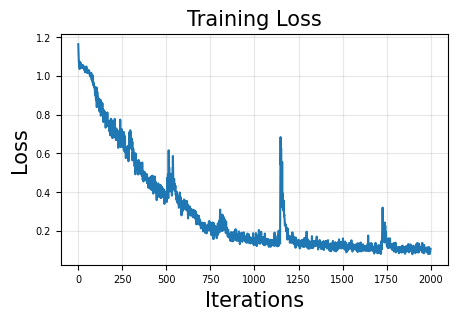

In [10]:
plt.figure(figsize=(5, 3))
plt.plot(loss_log)
fontsize = 15
plt.title('Training Loss', fontsize=fontsize)
plt.xlabel('Iterations', fontsize=fontsize)
plt.ylabel('Loss', fontsize=fontsize)
plt.grid(True, alpha=0.3)
plt.show()

### 2.2.4 Evaluating the trained model

After training, we evaluate the model on each task separately.
For each task, we run several trials and measure the fraction of correct decisions. Performance is measured as the fraction of trials where the model selects the correct action. These results show how well the RNN performs on each of the 20 tasks.

In [ ]:
net.eval()
# Initialize performance storage for each environment
sl_mean_performance = {}
for e_i in env.envs:
    sl_mean_performance[e_i.spec.id] = []

EVAL_TRIALS = 100
# Evaluate for specified number of trials
print(f"Evaluating model performance across {EVAL_TRIALS} trials...\n")
for env_idx, e_i in enumerate(env.envs):
    data = {"action": [], "gt": [], "trial": []}
    total_correct = 0
    for trial_idx in range(EVAL_TRIALS):
        trial = e_i.new_trial()
        data["trial"].append(trial)
        ob, gt = e_i.ob, e_i.gt
        data["gt"].append(gt[-1])
        trial_length = ob.shape[0]

        # Add task identity as one-hot input
        env_one_hot = np.zeros((trial_length, len(env.envs)))
        env_one_hot[:, env_idx] = 1.0  # Set the current environment index to 1

        # Concatenate original observation with one-hot encoding
        ob_with_env = np.concatenate([ob, env_one_hot], axis=1)

        ob_with_env = ob_with_env[:, np.newaxis, :]  # Add batch dimension

        inputs = torch.from_numpy(ob_with_env).float().to(device)
        # hidden = sl_model.init_hidden(1, device)

        with torch.no_grad():
            outputs, hidden = net(inputs)
            pred_actions = torch.argmax(outputs, dim=2)
            data["action"].append(pred_actions[-1, 0].cpu().numpy())

        decision_idx = trial_length - 1
        is_correct = (gt[decision_idx] == pred_actions[decision_idx, 0].cpu().numpy())
        total_correct += is_correct

    accuracy = total_correct / EVAL_TRIALS
    sl_mean_performance[e_i.spec.id].append(accuracy)
    for key in data:
        if key != "trial":
            data[key] = np.array(data[key])

# Print average performance
print("Average performance across all environments:")

for e_i in env.envs:
    mean_acc_single = np.mean(sl_mean_performance[e_i.spec.id])
    print(f"{e_i.spec.id}: {mean_acc_single:.4f}")

performance_all = np.mean([sl_mean_performance[e_i.spec.id] for e_i in env.envs])
print('\nAverage performance:', performance_all)

Evaluating model performance across 100 trials...

Average performance across all environments:
yang19.go-v0: 1.0000
yang19.rtgo-v0: 1.0000
yang19.dlygo-v0: 1.0000
yang19.anti-v0: 1.0000
yang19.rtanti-v0: 1.0000
yang19.dlyanti-v0: 1.0000
yang19.dm1-v0: 0.9000
yang19.dm2-v0: 0.9100
yang19.ctxdm1-v0: 0.7600
yang19.ctxdm2-v0: 0.8300
yang19.multidm-v0: 0.9200
yang19.dlydm1-v0: 0.9600
yang19.dlydm2-v0: 0.9500
yang19.ctxdlydm1-v0: 0.8300
yang19.ctxdlydm2-v0: 0.6500
yang19.multidlydm-v0: 0.7800
yang19.dms-v0: 1.0000
yang19.dnms-v0: 1.0000
yang19.dmc-v0: 1.0000
yang19.dnmc-v0: 1.0000

Average performance: 0.9245000000000001


# 3. Continual learning

Continual learning studies how a model can learn tasks sequentially while retaining knowledge from earlier tasks. Unlike standard machine learning where all data are available at once, continual learning exposes tasks one by one. This often leads to catastrophic forgetting, where learning a new task degrades performance on previous ones.

Here we construct a continual learning setting with four tasks: *Go*, *Delay Go*, *Anti*, and *Delay Anti*.

## 3.1 Train the model

We train the model sequentially on these tasks and evaluate how well it retains earlier knowledge.

### 3.1.1 Construct the dataset

First we create the four environments and obtain the observation and action dimensions.

In [ ]:
task_ids = ["go", "anti", "dlygo", "dlyanti"]
task = [f"yang19.{task}-v0" for task in task_ids]
envs = [ngym.make(t, **kwargs) for t in task]
ob_size = envs[0].observation_space.shape[0]
act_size = envs[0].action_space.n
device = 'cuda:0' if torch.cuda.is_available() else 'cpu'
print(f"ob_size: {ob_size}, act_size: {act_size}"   )

ob_size: 5, act_size: 3
Repeat times: 0
Task: go
100 loss: 0.88028
200 loss: 0.23723
Task: anti
100 loss: 0.97415
200 loss: 0.18480
Task: dlygo
100 loss: 0.57820
200 loss: 0.05354
Task: dlyanti
100 loss: 0.96452
200 loss: 0.63725
Repeat times: 1
Task: go
100 loss: 0.31537
200 loss: 0.07154
Task: anti
100 loss: 1.08871
200 loss: 0.08366
Task: dlygo
100 loss: 0.39090
200 loss: 0.03345
Task: dlyanti
100 loss: 0.89772
200 loss: 0.16438
Repeat times: 2
Task: go
100 loss: 0.13206
200 loss: 0.04815
Task: anti
100 loss: 1.03693
200 loss: 0.49425
Task: dlygo
100 loss: 0.15139
200 loss: 0.00118
Task: dlyanti
100 loss: 0.88280
200 loss: 0.02455
Repeat times: 3
Task: go
100 loss: 0.33667
200 loss: 0.04886
Task: anti
100 loss: 0.77259
200 loss: 0.06039
Task: dlygo
100 loss: 0.08347
200 loss: 0.00211
Task: dlyanti
100 loss: 0.99532
200 loss: 0.06080
Repeat times: 4
Task: go
100 loss: 0.08040
200 loss: 0.04772
Task: anti
100 loss: 0.61540
200 loss: 0.05411
Task: dlygo
100 loss: 0.07731
200 loss: 0.00

### 3.1.2 Setup

We now define training hyperparameters and a function to evaluate the model on each task.

In [ ]:
hidden_size = 64
epoch_per_task = 200
repeat_times = 10
batch_size = 64
seq_len = 100
lr = 1e-3
net = SimpleNet(ob_size=ob_size+len(envs), num_h=hidden_size, act_size=act_size).to(device)
net.train()
test_perfs = np.zeros((repeat_times, len(envs), len(envs)))
env_vecs = np.eye(len(envs))
loss_logs = np.zeros((repeat_times, len(envs), epoch_per_task))

class_weights = torch.tensor([0.05] + [1.0]*(act_size - 1)).to(device)
criterion = nn.CrossEntropyLoss(weight=class_weights)


# The function runs several trials and returns the fraction of correct decisions.
def test(env, net, env_vec):
    perf = 0
    num_trial = 200
    net.eval()
    for i in range(num_trial):
        env.seed(i)
        env.new_trial()
        ob, gt = env.ob, env.gt
        ob = ob[:, np.newaxis, :]  # Add batch axis
        ob = np.concatenate([ob, env_vec.reshape(1,1,-1).repeat(ob.shape[0], 0).repeat(ob.shape[1],1)], axis=-1)
        inputs = torch.from_numpy(ob).type(torch.float).to(device)
        action_pred = net(inputs)[0]
        action_pred = action_pred.cpu().detach().numpy()
        action_pred = np.argmax(action_pred, axis=-1)
        perf += gt[-1] == action_pred[-1, 0]
    perf /= num_trial
    return perf

### 3.1.3 Training the model

The model is trained sequentially on each task. After finishing one task, we evaluate performance on all tasks. The tensor `test_perfs` stores performance after each training stage, allowing us to measure forgetting.

In [ ]:
for i in range(repeat_times):
    print(f'Repeat times: {i}')
    for j, env in enumerate(envs):
        print(f'Task: {task_ids[j]}')
        dataset = ngym.Dataset(env, batch_size=batch_size, seq_len=seq_len)
        env_vec = env_vecs[j]
        optimizer = torch.optim.Adam(net.parameters(), lr=lr, weight_decay=wd)
        running_loss = 0.0
        loss_log = np.zeros((epoch_per_task,))
        for k in range(epoch_per_task):
            inputs, labels = dataset()
            # Append task identity to the observation
            inputs = np.concatenate([inputs, env_vec.reshape(1,1,-1).repeat(inputs.shape[0], 0).repeat(inputs.shape[1],1)], axis=-1)
            inputs = torch.from_numpy(inputs).type(torch.float).to(device)
            labels = torch.from_numpy(labels.flatten()).type(torch.long).to(device)
            # forward + backward + optimize
            outputs, hidden = net(inputs)
            loss = criterion(outputs.reshape(-1, act_size), labels)
            loss.backward()
            optimizer.step()
            optimizer.zero_grad()
            loss_log[k, ] = loss.item()
            # print statistics
            running_loss += loss.item()
            if (k+1) % 100 == 0:
                print('{:d} loss: {:0.5f}'.format(k+1, running_loss / 100))
                running_loss = 0.0

        loss_logs[i, j] = loss_log
        # Evaluate performance on all tasks
        for l, env_test in enumerate(envs):
            perf = test(env_test, net, env_vecs[l])
            test_perfs[i, j, l] = perf
print('Finished Training')

## 3.2 Evaluate the model
We now visualize how performance changes as the model is trained sequentially on different tasks.

### 3.2.1 Plot the test performance
Each colored curve shows performance on one task over the course of continual learning. The shaded background indicates which task the model is currently being trained on.

Drops in previously learned tasks indicate forgetting.

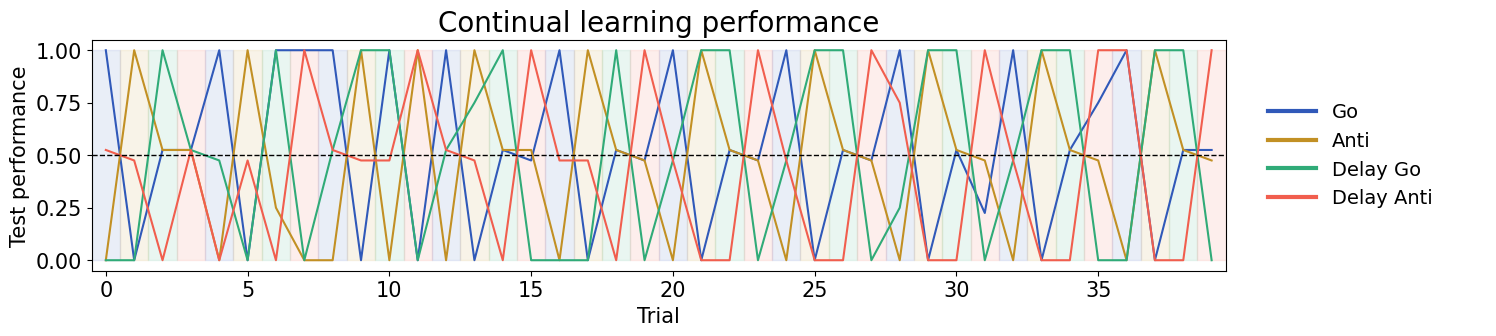

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

fontsize = 20

fig = plt.figure(figsize=(18, 3))
gs = fig.add_gridspec(1, 2, width_ratios=[5, 1], wspace=0.05)
ax_plot = fig.add_subplot(gs[0, 0])
ax_leg  = fig.add_subplot(gs[0, 1])
ax_leg.axis("off")

task_colors = [
    "#3059B9",
    "#C29024",
    "#30AB78",
    "#F15E4E",
]
task_names = ["Go", "Anti", "Delay Go", "Delay Anti"]
for j in range(len(envs)):
    env_perf = test_perfs[..., j].reshape(-1)
    ax_plot.plot(env_perf, color=task_colors[j])

for j in range(repeat_times):
    for k in range(len(envs)):
        ax_plot.fill_betweenx(
            [0, 1],
            j * len(envs) + k - 0.5,
            j * len(envs) + k + 0.5,
            color=task_colors[k],
            alpha=0.1
        )

ax_plot.set_xmargin(0)
ax_plot.set_xlabel("Trial", fontsize=fontsize - 5)
ax_plot.set_ylabel("Test performance", fontsize=fontsize - 5)
ax_plot.tick_params(labelsize=fontsize - 5)
ax_plot.set_title("Continual learning performance", fontsize=fontsize)
ax_plot.axhline(0.5, color="k", linestyle="--", linewidth=1)

# ----- legend on a separate axis (NOT attached to ax_plot) -----
handles = [
    Line2D([0], [0], color=task_colors[i], lw=3, label=task_names[i])
    for i in range(len(envs))
]

ax_leg.legend(
    handles=handles,
    loc="center left",
    frameon=False,
    fontsize=fontsize - 6,
    handlelength=2.5,
    borderaxespad=0.0,
)

plt.show()

### 3.2.2 Plot the average performance
We also plot the average performance across all tasks to summarize overall continual learning ability. This average gives a compact view of both learning and forgetting.

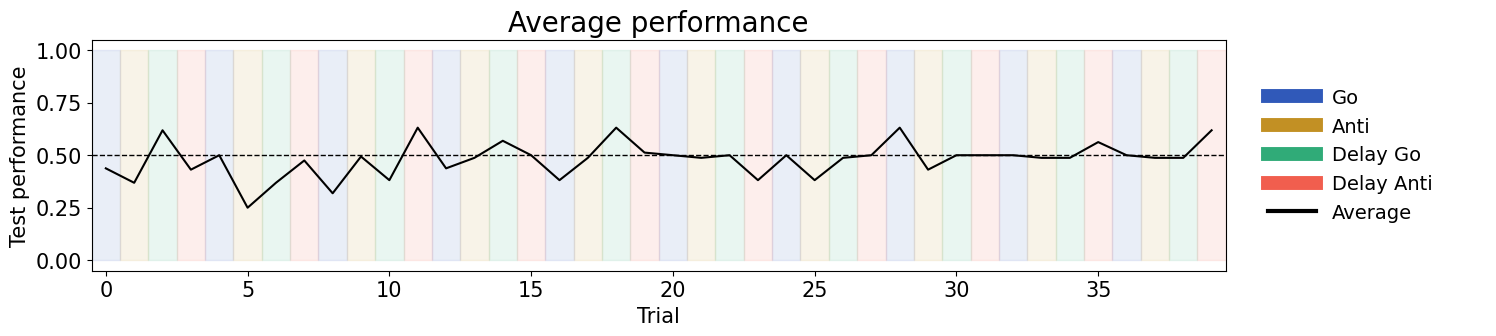

In [ ]:
avg_perfs = test_perfs.mean(-1).reshape(-1)
fig = plt.figure(figsize=(18, 3))
gs = fig.add_gridspec(1, 2, width_ratios=[5, 1], wspace=0.05)
ax_plot = fig.add_subplot(gs[0, 0])
ax_leg  = fig.add_subplot(gs[0, 1])
ax_leg.axis("off")


ax_plot.plot(avg_perfs, color='black')
for j in range(repeat_times):
    for k in range(len(envs)):
        ax_plot.fill_betweenx(
            [0, 1],
            j * len(envs) + k - 0.5,
            j * len(envs) + k + 0.5,
            color=task_colors[k],
            alpha=0.1
        )

ax_plot.set_xmargin(0)
ax_plot.set_xlabel("Trial", fontsize=fontsize - 5)
ax_plot.set_ylabel("Test performance", fontsize=fontsize - 5)
ax_plot.tick_params(labelsize=fontsize - 5)
ax_plot.set_title("Average performance", fontsize=fontsize)
ax_plot.axhline(0.5, color="k", linestyle="--", linewidth=1)

legend_labels = task_names + ['Average']
handles = [
    Line2D([0], [0], color=task_colors[i], lw=10, label=legend_labels[i])
    for i in range(len(envs))
] + [Line2D([0], [0], color='black', lw=3, label=legend_labels[-1])]

ax_leg.legend(
    handles=handles,
    loc="center left",
    frameon=False,
    fontsize=fontsize - 6,
    handlelength=2.5,
    borderaxespad=0.0,
)
plt.show()

### 3.2.3 Plot the loss curve
Finally, we plot the training loss throughout continual learning. Again, the colored regions indicate which task was being trained at each stage.

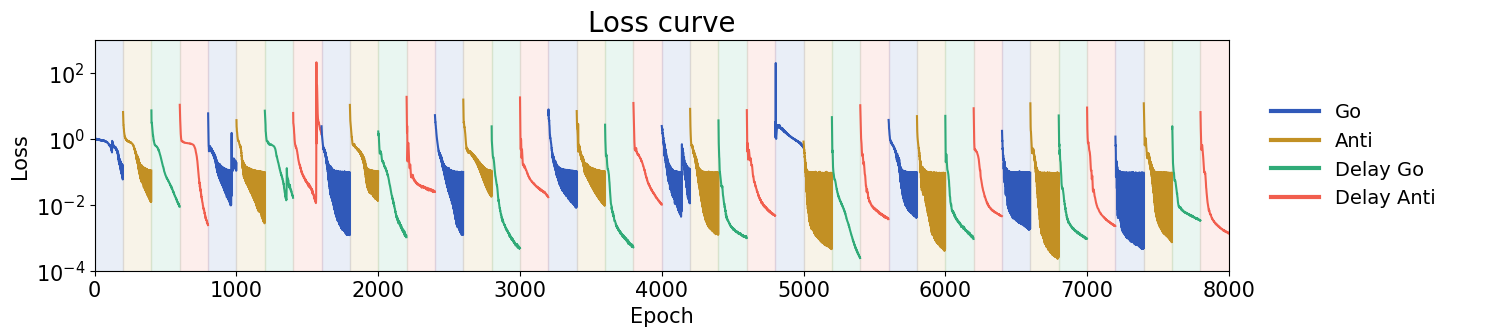

In [ ]:
lower_lim = 1e-4
upper_lim = 1e3
fig = plt.figure(figsize=(18, 3))
gs = fig.add_gridspec(1, 2, width_ratios=[5, 1], wspace=0.05)
ax_plot = fig.add_subplot(gs[0, 0])
ax_leg  = fig.add_subplot(gs[0, 1])
ax_leg.axis("off")
for i in range(repeat_times):
    for j in range(len(envs)):
        idx = i*len(envs)+j
        ax_plot.plot(np.arange(idx*epoch_per_task, (idx+1)*epoch_per_task), loss_logs[i,j], label=f'Env {i+1}', color=task_colors[j])
        ax_plot.fill_betweenx([lower_lim, upper_lim], idx*epoch_per_task, (idx+1)*epoch_per_task, color=task_colors[j], alpha=0.1)
ax_plot.set_xmargin(0)
ax_plot.set_xlabel('Epoch', fontsize=fontsize-5)
ax_plot.set_ylabel('Loss', fontsize=fontsize-5)
ax_plot.set_title('Loss curve', fontsize=fontsize)
ax_plot.tick_params(labelsize=fontsize-5)
ax_plot.set_ylim([lower_lim, upper_lim])
ax_plot.set_yscale('log')

handles = [
    Line2D([0], [0], color=task_colors[i], lw=3, label=task_names[i])
    for i in range(len(envs))
]

ax_leg.legend(
    handles=handles,
    loc="center left",
    frameon=False,
    fontsize=fontsize - 6,
    handlelength=2.5,
    borderaxespad=0.0,
)
plt.show()
